**Je commence par importer les outils :**

 **pandas** pour les tableaux,

**NumPy** pour le calcul et le hasard,
**Matplotlib** et **Seaborn** pour les graphiques,  
**scikit-learn** pour les deux modèles d'IA.

In [11]:
from IPython.display import display

# Étape 1 – Importer les outils

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

COULEUR = "#1F6F78"     # couleur des graphiques
ACCENT = "#E9A23B"      # couleur d'accent

In [12]:
# Étape 2 – Le tableau des services (données fictives)


services = pd.DataFrame([
    # service, étude technique, visite, autre administration, juridique, pièces min, pièces max, délai moyen, écart, poids
    ['extrait naissance/décès', 0, 0, 0, 0, 1, 1, 0, 0, 25],
    ['copie conforme', 0, 0, 0, 0, 1, 5, 0, 0, 25],
    ['vocation urbanistique', 0, 0, 0, 1, 5, 5, 7, 1, 8],
    ['certificat de conformité', 1, 1, 0, 0, 5, 5, 30, 4, 6],
    ['enseigne publicitaire', 1, 0, 0, 1, 6, 6, 15, 3, 5],
    ["autorisation d'installation", 0, 1, 1, 0, 5, 6, 15, 3, 5],
    ['occupation voie publique', 1, 1, 1, 0, 6, 6, 20, 2, 5],
    ['exploitation local commercial', 0, 1, 1, 1, 6, 7, 30, 5, 6],
    ['permis de bâtir', 1, 0, 1, 1, 9, 9, 21, 3, 7],
    ['permis de lotir', 1, 1, 1, 1, 8, 8, 45, 6, 3],
    ['permis de démolir', 1, 1, 1, 1, 4, 4, 60, 5, 3],
    ['régularisation construction', 1, 1, 1, 1, 7, 7, 90, 10, 2]
], columns=["service", "etude_technique", "visite_sur_place", "autre_administration",
            "examen_juridique", "pieces_min", "pieces_max", "delai_moyen", "ecart", "poids"])

criteres = ["etude_technique", "visite_sur_place", "autre_administration", "examen_juridique"]
services["complexite"] = 1 + services[criteres].sum(axis=1)

display(services[["service", "complexite", "pieces_min", "pieces_max", "delai_moyen"]])

,service,complexite,pieces_min,pieces_max,delai_moyen
0,extrait naissance/décès,1,1,1,0
1,copie conforme,1,1,5,0
2,vocation urbanistique,2,5,5,7
3,certificat de conformité,3,5,5,30
4,enseigne publicitaire,3,6,6,15
5,autorisation d'installation,3,5,6,15
6,occupation voie publique,4,6,6,20
7,exploitation local commercial,4,6,7,30
8,permis de bâtir,4,9,9,21
9,permis de lotir,5,8,8,45


Ce tableau décrit **12 services** d'**une Mairie**, avec leurs pièces et leur délai habituel.

 **La complexité va de 1 à 5 :** c'est 1 + le nombre de critères remplis (étude technique, visite sur place, accord d'une autre administration, examen juridique).

**Elle dépend donc de ce que le client demande, pas du nombre de pièces :** le permis de démolir n'a que 4 pièces mais sa complexité est 5.

Comme je n'ai pas de vraies données, je simule **1000 demandes** à partir de ces services, avec un petit hasard autour du délai habituel.

**Chaque ligne est une demande :** son type, sa complexité, son nombre de pièces et son délai en jours.

In [13]:
#  Étape 3 – Fabriquer 1000 demandes

rng = np.random.default_rng(42)   # 42 = pour obtenir toujours les mêmes résultats
n = 1000

poids = services["poids"] / services["poids"].sum()
choix = services.iloc[rng.choice(len(services), n, p=poids)].reset_index(drop=True)

nb_pieces = rng.integers(choix["pieces_min"], choix["pieces_max"] + 1)
delai = (choix["delai_moyen"] + rng.normal(0, 1, n) * choix["ecart"]).clip(lower=0).round()

df = pd.DataFrame({"type": choix["service"], "complexite": choix["complexite"],
                   "nb_pieces": nb_pieces, "delai": delai})
df.to_csv("demandes.csv", index=False)
display(df.head(10))

,type,complexite,nb_pieces,delai
0,occupation voie publique,4,6,23.0
1,copie conforme,1,5,0.0
2,permis de bâtir,4,9,21.0
3,autorisation d'installation,3,5,15.0
4,extrait naissance/décès,1,1,0.0
5,permis de démolir,5,4,69.0
6,occupation voie publique,4,6,15.0
7,occupation voie publique,4,6,16.0
8,extrait naissance/décès,1,1,0.0
9,copie conforme,1,2,0.0


(1000, 4)
type          0
complexite    0
nb_pieces     0
delai         0
dtype: int64


,complexite,nb_pieces,delai
count,1000.000000,1000.000000,1000.000000
mean,2.267000,4.075000,13.064000
std,1.432398,2.570989,18.818449
min,1.000000,1.000000,0.000000
25%,1.000000,1.000000,0.000000
50%,1.000000,5.000000,0.000000
75%,4.000000,6.000000,21.000000
max,5.000000,9.000000,113.000000


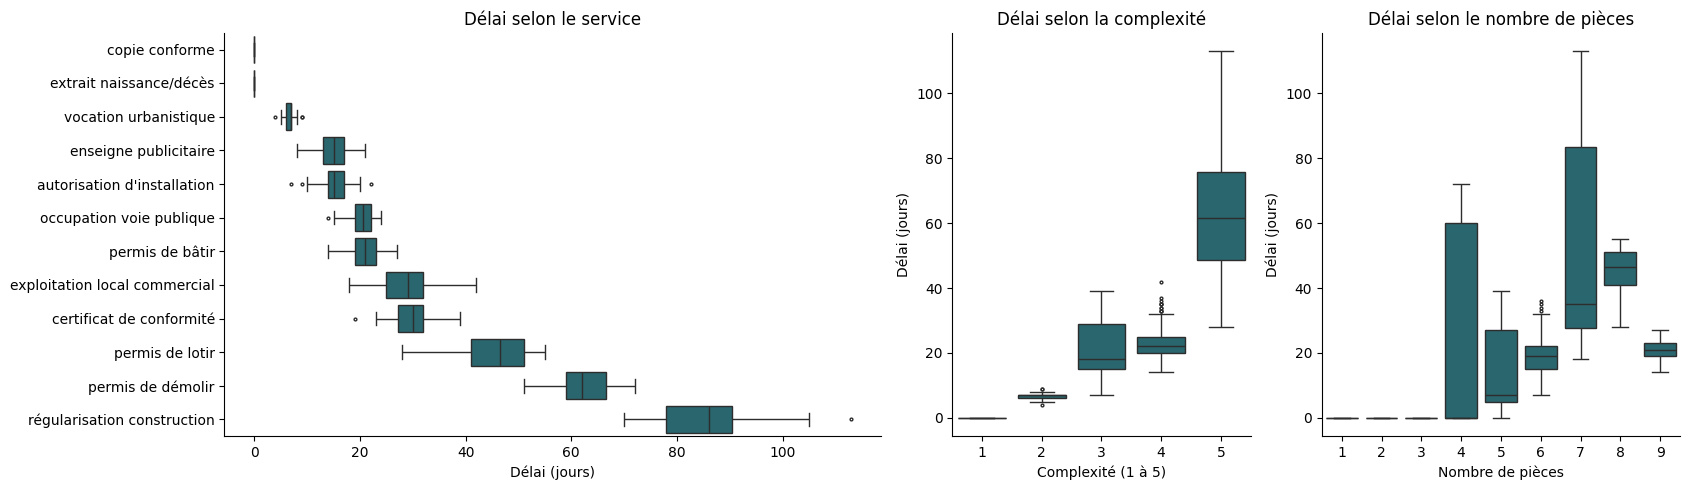

In [14]:
# Étape 4 – Regarder les données

print(df.shape)          # (nombre de lignes, nombre de colonnes)
print(df.isna().sum())  # valeurs manquantes ? (on espère 0)
display(df.describe())           # moyenne, min, max de chaque colonne

ordre = df.groupby("type")["delai"].median().sort_values().index
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [2.2, 1, 1.2]})

sns.boxplot(data=df, y="type", x="delai", order=ordre, color=COULEUR, linewidth=1, fliersize=2, ax=ax[0])
ax[0].set_title("Délai selon le service")
ax[0].set_xlabel("Délai (jours)"); ax[0].set_ylabel("")

sns.boxplot(data=df, x="complexite", y="delai", color=COULEUR, linewidth=1, fliersize=2, ax=ax[1])
ax[1].set_title("Délai selon la complexité")
ax[1].set_xlabel("Complexité (1 à 5)"); ax[1].set_ylabel("Délai (jours)")

sns.boxplot(data=df, x="nb_pieces", y="delai", color=COULEUR, linewidth=1, fliersize=2, ax=ax[2])
ax[2].set_title("Délai selon le nombre de pièces")
ax[2].set_xlabel("Nombre de pièces"); ax[2].set_ylabel("Délai (jours)")

sns.despine(fig)
plt.tight_layout()
plt.savefig("fig1_exploration.png", dpi=150)
plt.show()


Le tableau contient **1000 demandes** et **4 colonnes**, sans valeur manquante.

Le délai moyen est d'environ 13 jours, mais beaucoup de demandes sont à 0 jour (extraits et copies conformes).

**Sur les graphiques, plus la complexité monte, plus le délai est long.**

**Le nombre de pièces seul ne suffit pas :** une copie conforme peut avoir 5 pièces et rester à 0 jour.

# **Un modèle ne comprend que des nombres.**

Je transforme donc le type de demande en colonnes de 0 et de 1.

 Puis je sépare les données : **800 demandes pour apprendre et 200 pour tester le modèle sur des cas qu'il n'a jamais vus.**

In [15]:
# Étape 5 – Préparer les données

X = pd.get_dummies(df[["type", "complexite", "nb_pieces"]], columns=["type"], dtype=int)
y = df["delai"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Apprentissage :", X_train.shape[0], "demandes")
print("Test          :", X_test.shape[0], "demandes")
display(X.head())


Apprentissage : 800 demandes
Test          : 200 demandes


,complexite,nb_pieces,type_autorisation d'installation,type_certificat de conformité,type_copie conforme,type_enseigne publicitaire,type_exploitation local commercial,type_extrait naissance/décès,type_occupation voie publique,type_permis de bâtir,type_permis de démolir,type_permis de lotir,type_régularisation construction,type_vocation urbanistique
0,4,6,0,0,0,0,0,0,1,0,0,0,0,0
1,1,5,0,0,1,0,0,0,0,0,0,0,0,0
2,4,9,0,0,0,0,0,0,0,1,0,0,0,0
3,3,5,1,0,0,0,0,0,0,0,0,0,0,0
4,1,1,0,0,0,0,0,1,0,0,0,0,0,0


J'entraîne deux modèles : **la régression linéaire** et **le Random Forest**.



In [16]:
# Étape 6 – Entraîner et évaluer les 2 modèles

modeles = {
    "Régression linéaire": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

resultats = []
predictions = {}
for nom, modele in modeles.items():
    modele.fit(X_train, y_train)            # apprentissage
    pred = modele.predict(X_test)           # prédictions sur le test
    predictions[nom] = pred
    resultats.append({
        "Modèle": nom,
        "MAE (jours)": round(mean_absolute_error(y_test, pred), 2),
        "RMSE (jours)": round(mean_squared_error(y_test, pred) ** 0.5, 2),
        "R²": round(r2_score(y_test, pred), 3),
        "% à ±1 jour": round(100 * (abs(y_test - pred) <= 1).mean(), 1),
    })

tableau = pd.DataFrame(resultats)
display(tableau)


,Modèle,MAE (jours),RMSE (jours),R²,% à ±1 jour
0,Régression linéaire,1.68,2.92,0.979,59.5
1,Random Forest,1.69,2.92,0.979,60.0


Les deux se trompent d'environ 1,7 jour en moyenne (MAE), avec un R² de 0,98, et environ 60 % de leurs prédictions sont à moins d'un jour du vrai délai.

**Ils sont à égalité, parce que mes données suivent des règles claires et faciles à retrouver.**

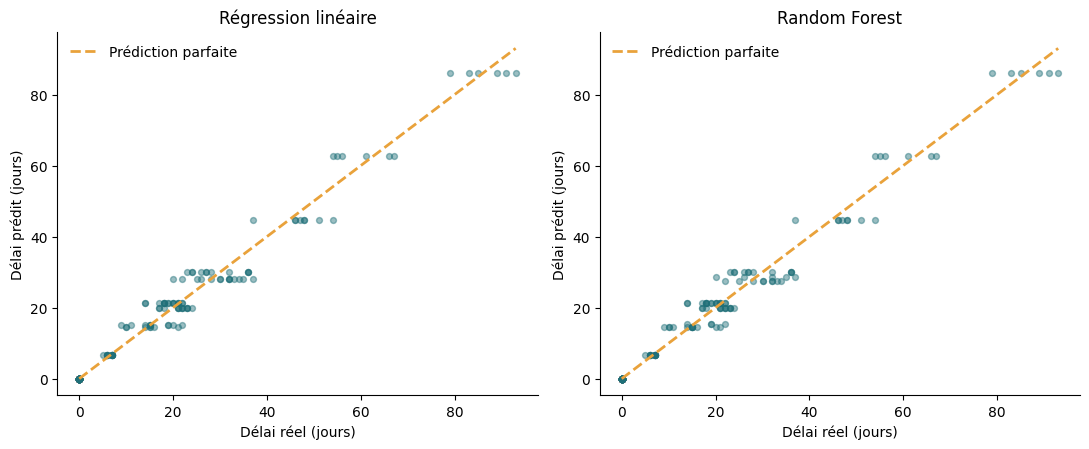

In [17]:
# Étape 7 – Prédit vs réel

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for a, (nom, pred) in zip(ax, predictions.items()):
    a.scatter(y_test, pred, s=18, alpha=0.45, color=COULEUR)
    m = [y_test.min(), y_test.max()]
    a.plot(m, m, "--", color=ACCENT, linewidth=2, label="Prédiction parfaite")
    a.set_xlabel("Délai réel (jours)")
    a.set_ylabel("Délai prédit (jours)")
    a.set_title(nom)
    a.legend(frameon=False)
sns.despine(fig)
plt.tight_layout()
plt.savefig("fig2_predit_vs_reel.png", dpi=150)
plt.show()

Chaque point est une demande du jeu de test.

Plus il est proche de la ligne orange, meilleure est la prédiction.

**Pour les deux modèles, les points suivent de près la ligne.**

Nombre de pièces     0.7 %
Type de demande      8.3 %
Complexité          91.0 %
dtype: object


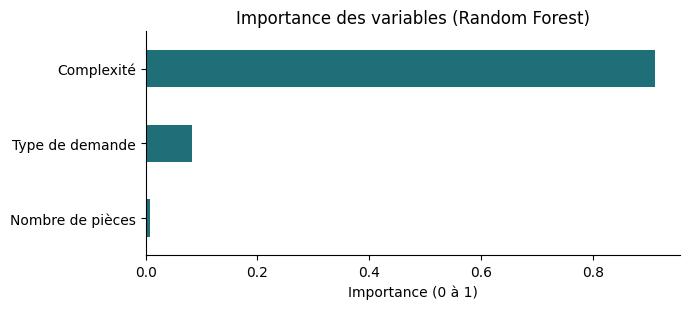

In [18]:
# Étape 8 – Qu'est-ce qui compte le plus pour le modèle ?

rf = modeles["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns)

# On regroupe toutes les colonnes "type_..." en une seule variable : le type de demande
groupes = pd.Series({
    "Type de demande": imp[[c for c in X.columns if c.startswith("type_")]].sum(),
    "Complexité": imp["complexite"],
    "Nombre de pièces": imp["nb_pieces"],
}).sort_values()
print((groupes * 100).round(1).astype(str) + " %")

ax = groupes.plot(kind="barh", color=COULEUR, figsize=(7, 3.2), title="Importance des variables (Random Forest)")
ax.set_xlabel("Importance (0 à 1)")
sns.despine()
plt.tight_layout()
plt.savefig("fig3_importance.png", dpi=150)
plt.show()



Le Random Forest montre ce qui compte le plus :
* la complexité représente 91 % de l'importance,
* le type de demande 8 % ,
*  le nombre de pièces moins de 1 %.

**Cela confirme que ce qui rend une demande longue, c'est ce que le client demande, pas le nombre de papiers.**

**Démonstration :**

In [19]:
# Étape 9 – Tester une nouvelle demande (démonstration)

type_demande = "copie conforme"  #@param ["extrait naissance/décès", "copie conforme", "vocation urbanistique", "certificat de conformité", "enseigne publicitaire", "autorisation d'installation", "occupation voie publique", "exploitation local commercial", "permis de bâtir", "permis de lotir", "permis de démolir", "régularisation construction"]
nb_pieces_demande = 3  #@param {type:"slider", min:1, max:10, step:1}

cplx = int(services.loc[services["service"] == type_demande, "complexite"].iloc[0])

nouvelle = pd.DataFrame([{"complexite": cplx, "nb_pieces": nb_pieces_demande}])
for t in services["service"]:
    nouvelle["type_" + t] = int(t == type_demande)
nouvelle = nouvelle[X.columns]      # même ordre de colonnes qu'à l'entraînement

print(f"Demande : {type_demande} | complexité {cplx} | {nb_pieces_demande} pièces")
for nom, modele in modeles.items():
    print(f"  {nom} : {max(modele.predict(nouvelle)[0], 0):.1f} jours")



Demande : copie conforme | complexité 1 | 3 pièces
  Régression linéaire : 0.0 jours
  Random Forest : 0.0 jours


**Je choisis un service et un nombre de pièces, et le modèle prédit le délai.**

Par exemple, pour un permis de bâtir avec 9 pièces, il prédit environ 21 jours, ce qui correspond au délai de référence.

# **Conclusion :**

Un modèle simple peut prédire le délai d'une demande avec environ 1,7 jour d'erreur.

La complexité est le facteur le plus important.

**Limite :** les données sont simulées, donc avec de vraies données de la mairie
les résultats seraient moins parfaits et il faudrait réentraîner le modèle.